
# **Neural Networks Decision Boundaries**

In this section, we will use a simple **2D synthetic dataset** (Two-Moons) to:
- Understand what a **decision boundary** is.
- See how a **neural network** learns a boundary from data.
- Explore two key hyperparameters:
  - `hidden_layer_sizes` (how many neurons and layers)
  - `activation` (how each neuron reacts to inputs)

We will start with a very simple model (no hidden layer — like logistic regression) and then add:
- A hidden layer with a few neurons.
- Different activation functions (`tanh` and `relu`).

The goal is to **see** how changing these choices changes the **shape of the decision boundary** and the model’s performance.



## **Two-Moons Dataset: Our Toy Problem**

The **Two-Moons dataset** is a classic example where:
- The classes are not separable by a straight line.
- A linear model (like plain logistic regression) will struggle.
- A neural network with a hidden layer can learn a **curved boundary**.

Each point has:
- 2 input features (x and y coordinates).
- 1 class label (0 or 1).


In [ ]:
from sklearn.datasets import make_moons

# Create nonlinear dataset
X, y = make_moons(n_samples=500, noise=0.2, random_state=42)

In [ ]:
from sklearn.model_selection import train_test_split
# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

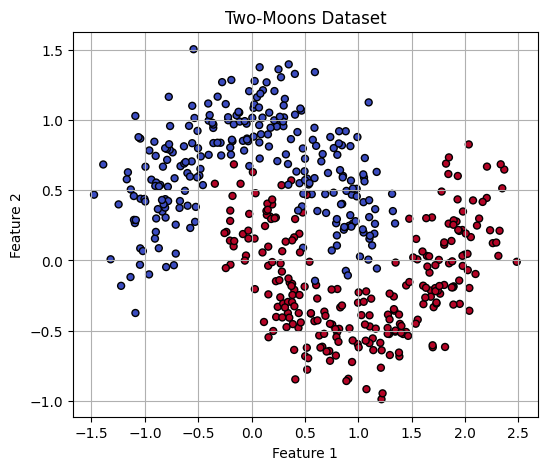

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Visualize dataset
plt.rcParams["figure.figsize"] = (6, 5)
plt.rcParams["axes.grid"] = True

plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolor="k", s=25)
plt.title("Two-Moons Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

## Visualizing the Decision Boundary

To understand what the neural network is doing, we will visualize the **decision boundary**:

- The decision boundary is the line (or curve) where the model is **uncertain** between classes.
- On one side of the boundary, the model predicts class 0; on the other side, class 1.

## Comparing Neural Network Architectures (2×3 Subplot)

In this section, we will train **six different neural network architectures** and compare their decision boundaries side-by-side.

This lets us SEE:
- How model complexity increases
- How hidden layers change learning ability
- How activation functions shape the boundary
- How deeper networks behave

We use the same dataset and same hyperparameters except:
- Number of hidden layers
- Number of neurons
- Activation function

This makes the comparison fair and meaningful.


In [ ]:
# Six architectures increasing in complexity

# define architectures
architectures = [
    ("identity", ()), # 1. Linear model, no hidden layers
    ("relu", (2,)),   # 2. HL, 2 neurons
    ("relu", (6,)),   # 3. HL, 6 neurons
    ("tanh", (6,)),   # 4. HL, 6 neurons (Tanh)
    ("tanh", (12,)),   # 4. HL, 12 neurons
    ("relu", (12,6))   # 3. HL, (12 -> 6) neurons deeper nt
]


titles = [
    "Linear Model",
    "1 HL (2), ReLU",
    "1 HL (3), ReLU",
    "1 HL (3), Tanh",
    "1 HL (6), Tanh",
    "2 HL (6, 6), ReLU"
]


learning_rate = 0.03
max_iter = 3000


**Train All Six Models**

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

models = []

for act, layers in architectures:
    clf = MLPClassifier(
        hidden_layer_sizes=layers,
        activation=act,
        learning_rate_init=learning_rate,
        max_iter=max_iter,
        random_state=42
    )
    clf.fit(X_train, y_train)
    models.append(clf)

In [ ]:
models

[MLPClassifier(activation='identity', hidden_layer_sizes=(),
               learning_rate_init=0.03, max_iter=3000, random_state=42),
 MLPClassifier(hidden_layer_sizes=(2,), learning_rate_init=0.03, max_iter=3000,
               random_state=42),
 MLPClassifier(hidden_layer_sizes=(6,), learning_rate_init=0.03, max_iter=3000,
               random_state=42),
 MLPClassifier(activation='tanh', hidden_layer_sizes=(6,),
               learning_rate_init=0.03, max_iter=3000, random_state=42),
 MLPClassifier(activation='tanh', hidden_layer_sizes=(12,),
               learning_rate_init=0.03, max_iter=3000, random_state=42),
 MLPClassifier(hidden_layer_sizes=(12, 6), learning_rate_init=0.03,
               max_iter=3000, random_state=42)]

**Plot All Six Models**

In [ ]:
def plot_boundary(model, X, y, ax, title):
    x_min, x_max = X[:, 0].min() - .5, X[:, 0].max() + .5
    y_min, y_max = X[:, 1].min() - .5, X[:, 1].max() + .5

    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, 0.02),
        np.arange(y_min, y_max, 0.02)
    )

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.65)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm,
               edgecolor="k", s=20)

    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")

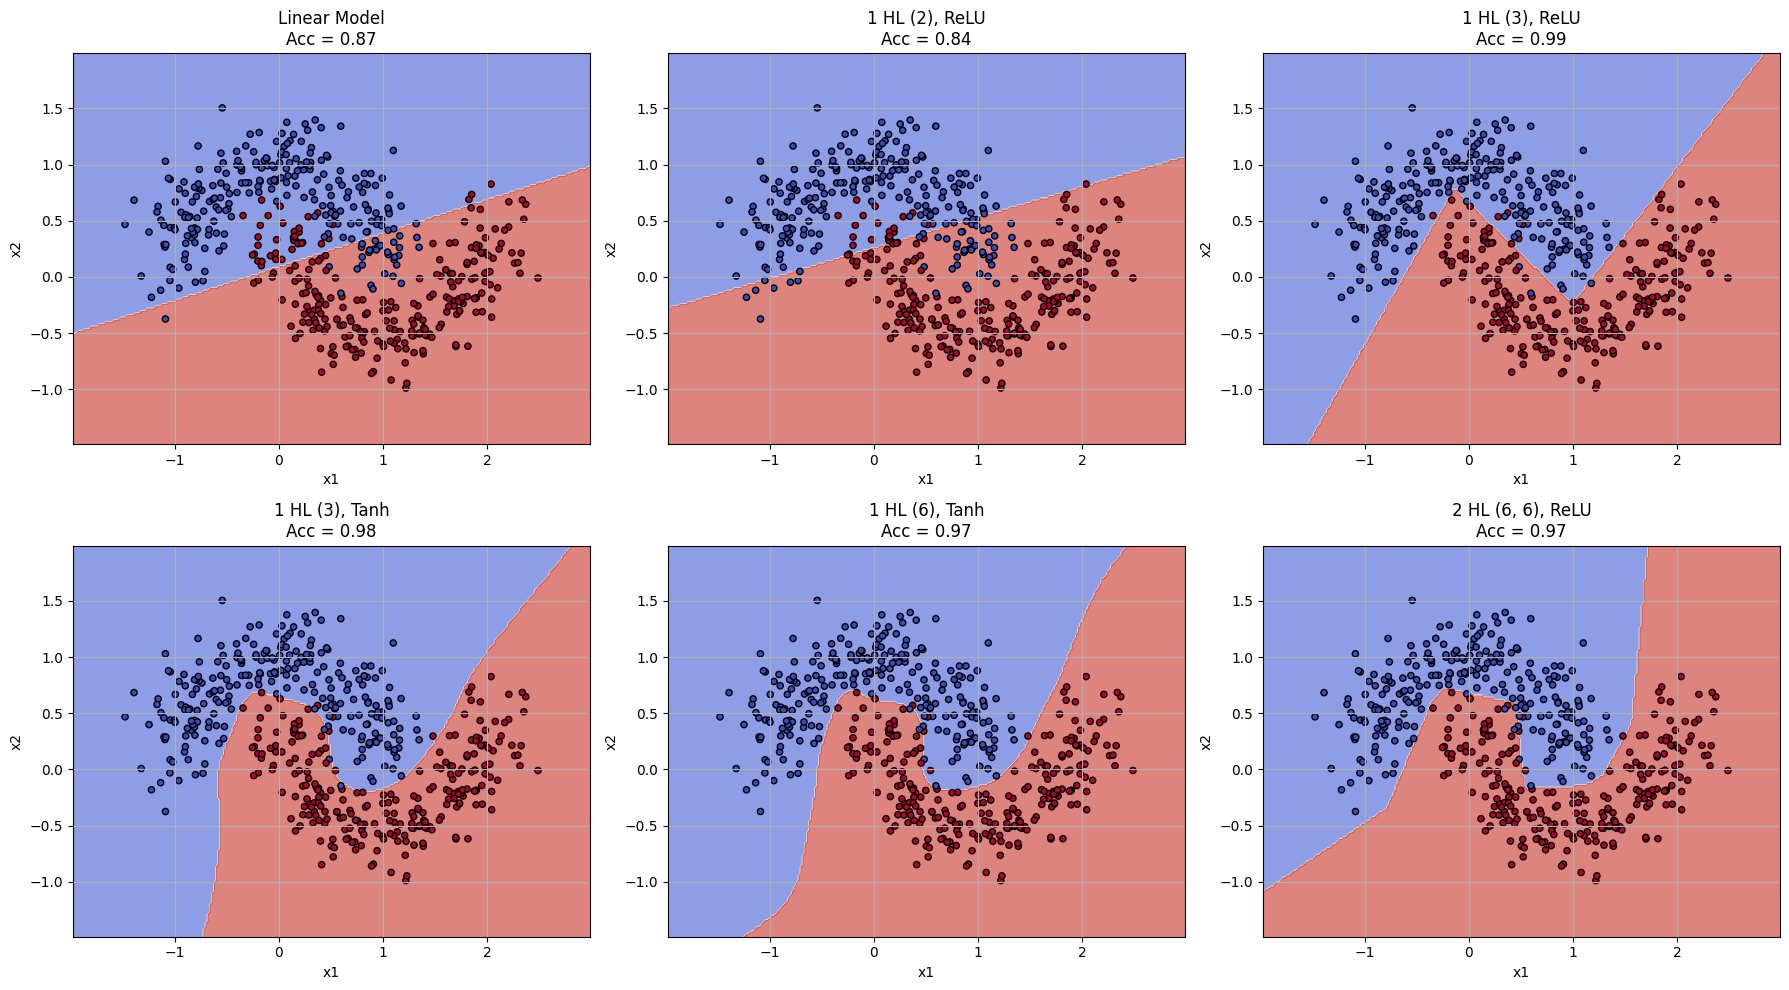

In [ ]:
# 2×3 subplot of all architectures

fig, axs = plt.subplots(2, 3, figsize=(18, 10))

for idx, model in enumerate(models):
    ax = axs[idx // 3, idx % 3]
    acc = accuracy_score(y_test, model.predict(X_test))
    plot_boundary(model, X, y, ax, f"{titles[idx]}\nAcc = {acc:.2f}")

plt.tight_layout()
plt.show()

- **Linear Model** → Only a straight line; cannot fit curved data.
- **1 HL (2), ReLU** → Too simple; boundary bends slightly but still underfits.
- **1 HL (3), ReLU** → More bends; captures shape much better.
- **1 HL (3), Tanh** → Smooth curve; follows data shape more naturally.
- **1 HL (6), Tanh** → More neurons = more flexible curve; high accuracy.
- **2 HL (6,6), ReLU** → Deeper network but not much better; extra layers don’t always help.


------
# **Neural Network Architecture Patterns**

Neural networks are not just **“more layers = better.”**  
Different shapes of networks fit different kinds of problems.

Below are five common architecture patterns used in real-world machine learning, with simple explanations and when to use each.

---

## What the Shape of a Network Controls

- **What patterns it can or cannot learn**
- **How well it generalizes** to new data
- **How it compresses or expands information**
- **How deeply it reasons** about features

Different shapes = different “brains” with different abilities.

---

## **Major Architecture Shapes (matching your visuals)**

Below are the major shapes and what they actually mean in simple terms.


## **1. Shallow Network (2 → 3 → 1)**

### What this shape means:
- Only one small hidden layer  

- The network forms just a few simple combinations of the inputs  
- It can detect very basic shapes or rules  
- Great for easy problems, but quickly underfits complex ones  



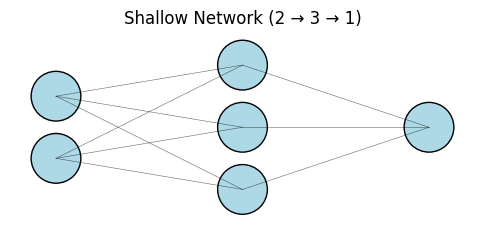

In [ ]:
visualize_mlp_structure([2, 3, 1], "Shallow Network (2 → 3 → 1)")

## **2. Equal-Width Network (8 → 8 → 8)**

### What this shape means:
- Each layer has the same number of neurons  
- Information flows evenly through the network  

### What happens inside:
- Each layer adds a similar level of complexity  
- The network transforms the data gradually and steadily  
- No layer compresses or expands too aggressively  



This shape is stable, predictable, and often used for business/tabular data.


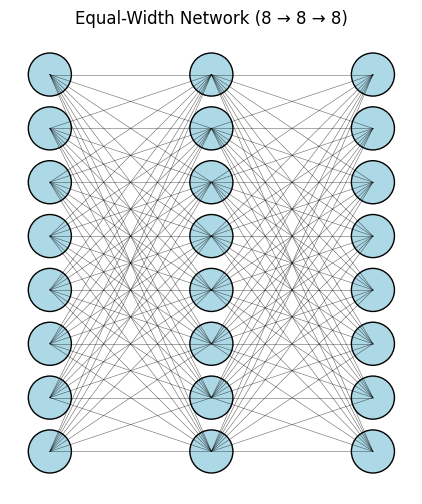

In [ ]:
visualize_mlp_structure([8, 8, 8], "Equal-Width Network (8 → 8 → 8)")

## **3. Pyramid Architecture (32 → 16 → 8 → 4)**

### What this shape means:
- Starts wide  
- Narrows down step-by-step  
- Gradual compression  

### What happens inside:
- Early layers learn many detailed features  
- Middle layers combine these into mid-level patterns  
- Final layers form high-level concepts  
- The network learns to filter and compress information as it moves forward  


***Think of a funnel:***  
Lots of raw data goes in, but only the important extracted meaning comes out.

This is why pyramids work very well for large, complex datasets.


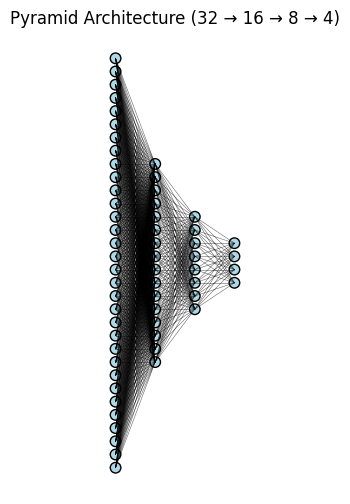

In [ ]:
visualize_mlp_structure([32, 16, 8, 4], "Pyramid Architecture (32 → 16 → 8 → 4)")

## **4. Bottleneck / Autoencoder Shape (32 → 16 → 4 → 16 → 32)**

### What this shape means:
- Middle layer is very small  
- The network must compress everything into just a few numbers  
- Then expand back out  

### What happens inside:
- The network is forced to learn the core essence of the input  
- Everything unimportant gets thrown away  
- It learns compressed representations automatically  



Networks with bottlenecks are powerful for anomaly detection, compression, and denoising.


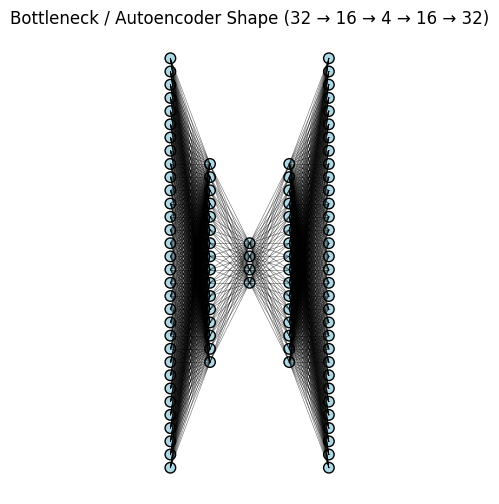

In [ ]:
visualize_mlp_structure([32, 16, 4, 16, 32], "Bottleneck / Autoencoder Shape (32 → 16 → 4 → 16 → 32)")

## **Why Does the Shape Matter?**

### **1. Depth = Ability to build layered understanding**
More layers → more abstract features.  
Like detecting:  
- edges → shapes → objects  
- small patterns → medium patterns → big patterns  

### **2. Width = Ability to memorize or separate points**
More neurons → more “space” to store learned patterns.

### **3. Compression (bottlenecks) forces the network to learn what truly matters**
Removes **noise**, **redundancy**, and **irrelevant features**.

### **4. Gradual narrowing (pyramid) creates strong generalization**
You start with many features → refine them → compress them → final prediction.

### **5. Shape controls bias vs variance**
- **Too small → underfits**  
- **Too large → overfits**  
- **Balanced shape → sweet spot**  


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_mlp_structure(layer_sizes, title="NN Architecture"):
    fig, ax = plt.subplots(figsize=(6,6))

    # grid spacing
    v_spacing = 1
    h_spacing = 3

    # draw layers
    for i, layer_size in enumerate(layer_sizes):
        x = i * h_spacing
        for j in range(layer_size):
            y = j * v_spacing - (layer_size * v_spacing)/2
            circle = plt.Circle((x, y), 0.4, fill=True, color="lightblue", ec="black")
            ax.add_patch(circle)

    # draw connections
    for i in range(len(layer_sizes)-1):
        for a in range(layer_sizes[i]):
            for b in range(layer_sizes[i+1]):
                x1, y1 = i * h_spacing, a * v_spacing - (layer_sizes[i] * v_spacing)/2
                x2, y2 = (i+1) * h_spacing, b * v_spacing - (layer_sizes[i+1] * v_spacing)/2
                ax.plot([x1, x2], [y1, y2], 'k-', lw=0.4, alpha=0.6)

    ax.set_title(title)
    ax.set_aspect('equal')
    ax.axis('off')
    plt.show()
